In [1]:
%pip install qiskit qiskit-aer matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

simulator = AerSimulator()

## Part A — Correlated Outcomes

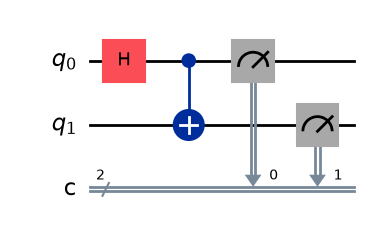

In [3]:
# Part A: Correlated Outcomes
circuit_A = QuantumCircuit(2, 2)

circuit_A.h(0)
circuit_A.cx(0, 1)

circuit_A.measure([0, 1], [0, 1])

display(Markdown("## Part A — Correlated Outcomes"))
display(circuit_A.draw(output="mpl"))

In [4]:
display(Markdown("""
## Prediction — Part A: Correlated Outcomes

- Expected dominant outcomes: 00 and 11.
- Predicted probability of 00: 50%.
- Predicted probability of 11: 50%.
- Outcomes 01 and 10 are not expected in an ideal simulator.
- For 100 shots, approximately 50 results of 00 and 50 results of 11 are expected.

Prediction: Both qubits will produce matching measurement outcomes.
"""))


## Prediction — Part A: Correlated Outcomes

- Expected dominant outcomes: 00 and 11.
- Predicted probability of 00: 50%.
- Predicted probability of 11: 50%.
- Outcomes 01 and 10 are not expected in an ideal simulator.
- For 100 shots, approximately 50 results of 00 and 50 results of 11 are expected.

Prediction: Both qubits will produce matching measurement outcomes.


In [5]:
result_A = simulator.run(circuit_A, shots=100).result()
counts_A = result_A.get_counts()

print("Part A — Correlated Outcomes")
print("Measurement results:", counts_A)
print("Total shots:", sum(counts_A.values()))

Part A — Correlated Outcomes
Measurement results: {'00': 59, '11': 41}
Total shots: 100


## Part B — Opposite Outcomes

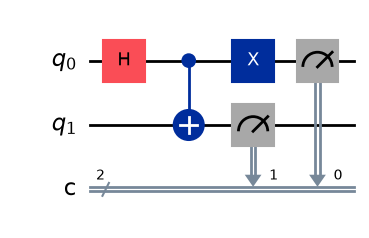

In [6]:
# Part B: Opposite Outcomes
circuit_B = QuantumCircuit(2, 2)

circuit_B.h(0)
circuit_B.cx(0, 1)
circuit_B.x(0)

circuit_B.measure([0, 1], [0, 1])

display(Markdown("## Part B — Opposite Outcomes"))
display(circuit_B.draw(output="mpl"))

In [7]:
display(Markdown("""
## Prediction — Part B: Opposite Outcomes

- Expected dominant outcomes: 01 and 10.
- Predicted probability of 01: 50%.
- Predicted probability of 10: 50%.
- Outcomes 00 and 11 are not expected in an ideal simulator.
- For 100 shots, approximately 50 results of 01 and 50 results of 10 are expected.

Prediction: The two qubits will produce opposite measurement outcomes.
"""))


## Prediction — Part B: Opposite Outcomes

- Expected dominant outcomes: 01 and 10.
- Predicted probability of 01: 50%.
- Predicted probability of 10: 50%.
- Outcomes 00 and 11 are not expected in an ideal simulator.
- For 100 shots, approximately 50 results of 01 and 50 results of 10 are expected.

Prediction: The two qubits will produce opposite measurement outcomes.


In [8]:
result_B = simulator.run(circuit_B, shots=100).result()
counts_B = result_B.get_counts()

print("Part B — Opposite Outcomes")
print("Measurement results:", counts_B)
print("Total shots:", sum(counts_B.values()))

Part B — Opposite Outcomes
Measurement results: {'10': 51, '01': 49}
Total shots: 100


In [9]:
display(Markdown("## Comparison of Measurement Results"))

outcomes = ["00", "01", "10", "11"]

comparison = pd.DataFrame({
    "Outcome": outcomes,
    "Part A — Correlated": [
        counts_A.get(outcome, 0) for outcome in outcomes
    ],
    "Part B — Opposite": [
        counts_B.get(outcome, 0) for outcome in outcomes
    ]
})

display(comparison)

## Comparison of Measurement Results

,Outcome,Part A — Correlated,Part B — Opposite
0,00,59,0
1,01,0,49
2,10,0,51
3,11,41,0


## Histograms — Part A vs Part B

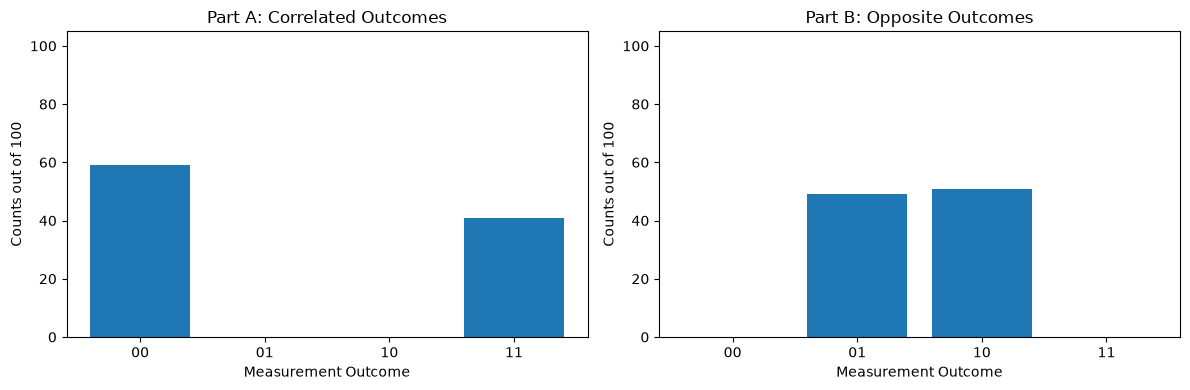

In [10]:
display(Markdown("## Histograms — Part A vs Part B"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    outcomes,
    [counts_A.get(outcome, 0) for outcome in outcomes]
)
axes[0].set_title("Part A: Correlated Outcomes")
axes[0].set_xlabel("Measurement Outcome")
axes[0].set_ylabel("Counts out of 100")
axes[0].set_ylim(0, 105)

axes[1].bar(
    outcomes,
    [counts_B.get(outcome, 0) for outcome in outcomes]
)
axes[1].set_title("Part B: Opposite Outcomes")
axes[1].set_xlabel("Measurement Outcome")
axes[1].set_ylabel("Counts out of 100")
axes[1].set_ylim(0, 105)

plt.tight_layout()
plt.show()

In [ ]:
## Explanation and Comparison

**1. Which outcomes are dominant in Part A?**

Outcomes 00 and 11 are dominant. Both qubits produce matching measurement outcomes, with approximately 50% probability for each outcome.

**2. Which outcomes are dominant in Part B?**

Outcomes 01 and 10 are dominant. The two qubits produce opposite measurement outcomes, with approximately 50% probability for each outcome.

**3. What changed between the two circuits?**

Part B adds one X gate to qubit 0 after the Hadamard and CNOT gates. Part A uses two quantum gates before measurement, while Part B uses three.

**4. Why did the measurement relationship change?**

The X gate flips qubit 0, changing the correlated Bell state into a state with opposite measurement outcomes. Therefore, Part A produces matching bits, whereas Part B produces different bits.

Both circuits were executed for 100 shots, and their measurement results were compared using histograms.